In [7]:
from ddd_policy_tracer.analysis.chunks.adapters import SQLiteDocumentChunkRepository


chunk_repo = SQLiteDocumentChunkRepository()

In [9]:
chunks = await chunk_repo.list_chunks()

In [10]:
chunks[0]

DocumentChunk(chunk_id='chunk_3523e1c2f442034b', source_id='australia_institute', source_document_id='https://australiainstitute.org.au/report/australias-reliance-on-income-tax', document_checksum='84a7ed956a701d0d21e5748bd05889b5b95cc3b0f8b2e4f5b4697ef27f4acc97', chunk_index=0, start_char=0, end_char=52, chunk_text='**==> picture [187 x 49] intentionally omitted <==**', embedding=[-0.0184326171875, -0.042724609375, -0.01031494140625, -0.051025390625, 0.00946044921875, 0.056884765625, 0.0113525390625, 0.026611328125, -0.029541015625, 0.01123046875, 0.0031890869140625, -0.037841796875, 0.0235595703125, -0.007720947265625, -0.05126953125, 0.059326171875, 0.0, 0.048828125, 0.1025390625, 0.01507568359375, -0.046142578125, 0.00592041015625, 0.00518798828125, 0.10205078125, 0.003265380859375, 0.037841796875, -0.00092315673828125, 0.056640625, 0.00970458984375, -0.0150146484375, 0.00732421875, 0.01220703125, -0.0771484375, -0.01324462890625, -0.03515625, -0.011962890625, -0.005828857421875, 0

In [11]:
import pandas as pd

df = pd.DataFrame([chunk.__dict__ for chunk in chunks])

array([[<Axes: title={'center': 'chunk_length'}>]], dtype=object)

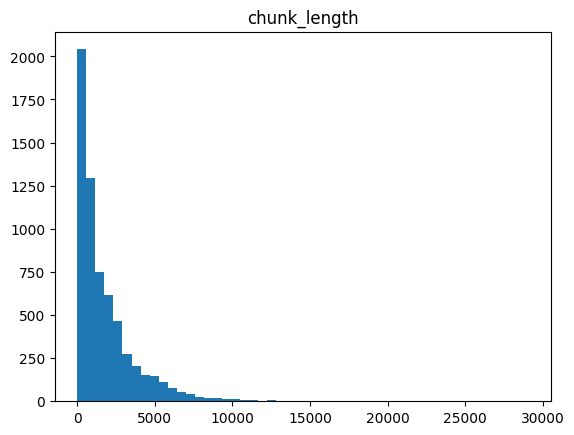

In [12]:
# get length of each chunk
df["chunk_length"] = df["chunk_text"].apply(len)
# plot with axis labels
df.hist(column="chunk_length", bins=50, grid=False)

In [14]:
df[~df.embedding.isna()]

,chunk_id,source_id,source_document_id,document_checksum,chunk_index,start_char,end_char,chunk_text,embedding,chunk_length
0,chunk_3523e1c2f442034b,australia_institute,https://australiainstitute.org.au/report/austr...,84a7ed956a701d0d21e5748bd05889b5b95cc3b0f8b2e4...,0,0,52,**==> picture [187 x 49] intentionally omitted...,"[-0.0184326171875, -0.042724609375, -0.0103149...",52
1,chunk_bc7890ac330de50f,australia_institute,https://australiainstitute.org.au/report/austr...,84a7ed956a701d0d21e5748bd05889b5b95cc3b0f8b2e4...,1,53,688,## **Income tax in Australia’s tax system Bust...,"[-0.09814453125, 0.01513671875, -0.00527954101...",635
2,chunk_1c1e4e23bf929e48,australia_institute,https://australiainstitute.org.au/report/austr...,84a7ed956a701d0d21e5748bd05889b5b95cc3b0f8b2e4...,2,689,1114,## **ABOUT THE AUSTRALIA INSTITUTE** \nThe Au...,"[-0.01141357421875, 0.0125732421875, -0.008056...",425
3,chunk_b20fd1b29b3fbcba,australia_institute,https://australiainstitute.org.au/report/austr...,84a7ed956a701d0d21e5748bd05889b5b95cc3b0f8b2e4...,3,1115,1740,## **OUR PHILOSOPHY** \nAs we begin the 21st ...,"[-0.048095703125, -0.0201416015625, -0.0100708...",625
4,chunk_ce93404b39c0db77,australia_institute,https://australiainstitute.org.au/report/austr...,84a7ed956a701d0d21e5748bd05889b5b95cc3b0f8b2e4...,4,1741,2713,## **OUR PURPOSE – ‘RESEARCH THAT MATTERS’** ...,"[-0.008056640625, 0.005645751953125, -0.008850...",972
...,...,...,...,...,...,...,...,...,...,...
6361,chunk_c6ffc6c8df7d26d0,australia_institute,https://australiainstitute.org.au/report/austr...,0e252c34fe2bbee49bf4598baeb84aa7dd87c43e1541c9...,41,88772,89149,## _8. A national renewable energy strategy_ ...,"[-0.02978515625, 0.024658203125, -0.0042114257...",377
6362,chunk_2c6fe631dc543a8a,australia_institute,https://australiainstitute.org.au/report/austr...,0e252c34fe2bbee49bf4598baeb84aa7dd87c43e1541c9...,42,89150,89670,## _9. Adopt a feasible greenhouse gas reduct...,"[-0.07958984375, 0.060791015625, -0.0027008056...",520
6367,chunk_0ef974f2f589d4bf,australia_institute,https://australiainstitute.org.au/report/the-p...,810564cee99f32625a007d941048ca5e06caa27c47ac3c...,2,110,328,## **THE PRIVATISATION OF CSL** \nDr Clive Ha...,"[-0.00141143798828125, -0.0242919921875, -0.01...",218
6368,chunk_a864ea5bb6eac033,australia_institute,https://australiainstitute.org.au/report/the-p...,810564cee99f32625a007d941048ca5e06caa27c47ac3c...,3,329,585,## **Contents** \n||Summary|1|\n|---|---|---|...,"[0.0, -0.047119140625, -0.01043701171875, -0.0...",256


In [16]:
len(df[df['chunk_length'] < 2500])

4851

In [7]:
from semantic_router.encoders import LocalEncoder
from semantic_chunkers import StatisticalChunker, ConsecutiveChunker

encoder = LocalEncoder(name="Qwen/Qwen3-Embedding-0.6B")
consec_chunker = ConsecutiveChunker(encoder=encoder)
chunker = StatisticalChunker(encoder=encoder, max_split_tokens=1000)

/Users/thomasscelsi/Documents/programming/ddd-policy-tracer/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
19:57:46 - LiteLLM:WARNING: common_utils.py:979 - litellm: could not pre-load bedrock-runtime response stream shape — Bedrock event-stream decoding will be unavailable. Error: No module named 'botocore'
2026-05-25 19:57:46 - LiteLLM - WARNING - common_utils.py:979 - _load_bedrock_response_stream_shape() - litellm: could not pre-load bedrock-runtime response stream shape — Bedrock event-stream decoding will be unavailable. Error: No module named 'botocore'
19:57:46 - LiteLLM:WARNING: common_utils.py:24 - litellm: could not pre-load sagemaker-runtime response stream shape — SageMaker event-stream decoding will be unavailable. Error: No module named 'botocore'
2026-05-25 19:57:46 - LiteLLM - WA

In [1]:
from ddd_policy_tracer.discovery.adapters import FilesystemSourceDocumentRepository
from pathlib import Path

doc_repo = FilesystemSourceDocumentRepository(Path("data/documents_new2.jsonl"))

doc = doc_repo.get_latest(source_id="australia_institute", source_document_id="https://australiainstitute.org.au/report/state-sponsored-greenwash")

In [9]:
statistical_chunks = chunker(docs=[doc.normalized_text])

2026-05-25 19:58:07 INFO semantic_chunkers.utils.logger Single document exceeds the maximum token limit of 1000. Splitting to sentences before semantically merging.
100%|██████████| 66/66 [00:44<00:00,  1.47it/s]


In [10]:
consecutive_chunks = consec_chunker(docs=[doc.normalized_text])

100%|██████████| 4218/4218 [00:00<00:00, 482769.59it/s]


In [6]:
from ddd_policy_tracer.analysis.chunks.chunking import MarkdownChunker
from ddd_policy_tracer.discovery.adapters import FilesystemSourceDocumentRepository
from pathlib import Path

doc_repo = FilesystemSourceDocumentRepository(Path("data/documents_new2.jsonl"))

doc = doc_repo.get_latest(source_id="australia_institute", source_document_id="https://australiainstitute.org.au/report/state-sponsored-greenwash")

chunker = MarkdownChunker(separators=["\n\n", "\n", " "])
md_chunks = chunker.chunk_document(doc=doc)

In [12]:
import textwrap

def visualise_texts(texts: list[str], width: int = 100):
    for text in texts:
        print('\n'.join(textwrap.wrap(text, width, break_long_words=False)))
        print('=' * width)
        print('=' * width)

def write_texts_to_file(texts: list[str], filename: str, width: int = 100):
    with open(filename, 'w') as f:
        for text in texts:
            f.write('\n'.join(textwrap.wrap(text, width, break_long_words=False)))
            f.write('\n' + '=' * width + '\n' + '=' * width + '\n')


In [3]:
# write_texts_to_file([x.content for x in consecutive_chunks[0]], "consecutive.txt")
# write_texts_to_file([x.content for x in statistical_chunks[0]], "statistical.txt")
write_texts_to_file([x.chunk_text for x in md_chunks], "markdown_chunks.txt")

In [ ]:
from ddd_policy_tracer.discovery.adapters import FilesystemSourceDocumentRepository
from pathlib import Path

doc_repo = FilesystemSourceDocumentRepository(Path("data/documents_new.jsonl"))
docs = doc_repo.list_versions(source_id="australia_institute")

In [4]:
from ddd_policy_tracer.discovery.adapters import pdf_text_to_md_australia_institute
from ddd_policy_tracer.discovery.domain import SourceDocument
new_docs = []
for doc in docs:
    print(f"Processing document: {doc.source_document_id}")
    doc_bytes = Path(doc.raw_content_ref).read_bytes()
    md_text = pdf_text_to_md_australia_institute(doc_bytes)
    new_docs.append(SourceDocument(
        source_id=doc.source_id,
        source_document_id=doc.source_document_id,
        source_url=doc.source_url,
        published_at=doc.published_at,
        retrieved_at=doc.retrieved_at,
        checksum=doc.checksum,
        normalized_text=md_text,
        raw_content_ref=doc.raw_content_ref,
        content_type=doc.content_type,
        created_at=doc.created_at,
        updated_at=doc.updated_at,
    ))

Processing document: https://australiainstitute.org.au/report/australias-reliance-on-income-tax
Processing document: https://australiainstitute.org.au/report/no-jobs-on-a-dead-planet
Processing document: https://australiainstitute.org.au/report/submission-delivering-fairer-and-bigger-returns-always
Processing document: https://australiainstitute.org.au/report/a-stronger-prrt-cap
Processing document: https://australiainstitute.org.au/report/democracy-agenda-for-the-51st-tasmanian-parliament
Processing document: https://australiainstitute.org.au/report/australias-fuel-tax-credits-and-the-debate-over-fossil-fuel-subsidies
Processing document: https://australiainstitute.org.au/report/polling-whistleblowing-secrecy
Processing document: https://australiainstitute.org.au/report/budget-2024-25-resists-austerity-reduces-inflation-targets-wage-gains
Processing document: https://australiainstitute.org.au/report/saved-by-the-bench
Processing document: https://australiainstitute.org.au/report/no-de

In [36]:
from ddd_policy_tracer.discovery.adapters import FilesystemSourceDocumentRepository
from pathlib import Path
doc_repo = FilesystemSourceDocumentRepository(Path("data/documents_new2.jsonl"))

In [37]:
docs = doc_repo.list_versions(source_id="hansard")

In [38]:
import pandas as pd

df = pd.DataFrame([part.__dict__ for part in docs])

In [5]:
df['chunk_length'] = df['normalized_text'].apply(len)

In [6]:
import textwrap

def visualise_texts(texts: list[str], width: int = 100):
    for text in texts:
        print('\n'.join(textwrap.wrap(text, width, break_long_words=False)))
        print('=' * width)
        print('=' * width)

visualise_texts(df.sort_values('chunk_length', ascending=False).head(10).normalized_text)

I present the government's response to the Community Affairs References Committee's report
entitledEndingthepostcode lottery: addressing barriers to sexual, maternity and reproductive
healthcare in Australia. In accordance with the usual practice, I seek leave to have the document
incorporated intoHansard.  Leave granted.  The document read as follows—  Australian Government
response to the Senate Community Affairs References Committee report:Ending the postcode
lottery—Addressing barriers to sexual, maternity and reproductive healthcare in Australia  Overview
On 28 September 2022, the Senate referred the issue of universal access to reproductive healthcare
to the Senate Community Affairs References Committee for inquiry and report.  Supporting,
protecting, and promoting the sexual and reproductive health and rights of all Australians is
critical to the Australian Government. The Government recognises the importance of ensuring access
to sexual and reproductive health information, trea

In [7]:
df.chunk_length.describe()

count     15399.000000
mean       2379.973635
std        3772.717226
min           0.000000
25%         106.000000
50%         913.000000
75%        3595.000000
max      109655.000000
Name: chunk_length, dtype: float64

array([[<Axes: title={'center': 'chunk_length'}>]], dtype=object)

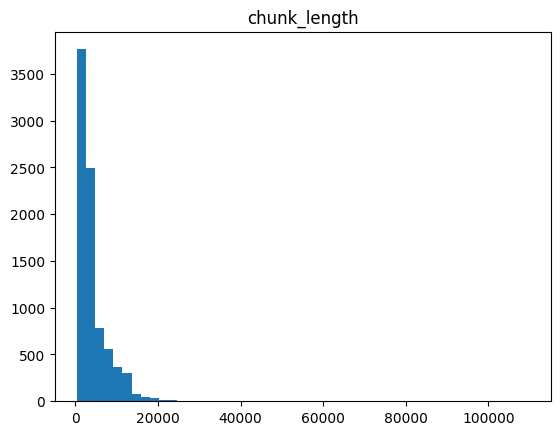

In [8]:
filtered_df = df[df['chunk_length'] > 500]
filtered_df.hist(column="chunk_length", bins=50, grid=False)

In [ ]:
from semantic_router.encoders import LocalEncoder
from semantic_chunkers import StatisticalChunker, ConsecutiveChunker

encoder = LocalEncoder(name="Qwen/Qwen3-Embedding-0.6B")
consec_chunker = ConsecutiveChunker(encoder=encoder, score_threshold=0.4)
chunker = StatisticalChunker(encoder=encoder, max_split_tokens=1000)

2026-05-25 23:32:25 - sentence_transformers.base.model - INFO - model.py:183 - __init__() - No device provided, using mps
2026-05-25 23:32:26 - sentence_transformers.base.model - INFO - model.py:992 - _load_modules() - Loading SentenceTransformer model from Qwen/Qwen3-Embedding-0.6B.
Loading weights: 100%|██████████| 310/310 [00:00<00:00, 21009.81it/s]
2026-05-25 23:32:35 - sentence_transformers.base.model - INFO - model.py:259 - _validate_prompts() - Loaded 1 prompt with these keys: ['query']


TypeError: MarkdownHeaderTextSplitter.__init__() got an unexpected keyword argument 'markdown_headers'

In [9]:
longest_doc = df.sort_values('chunk_length', ascending=False).iloc[0]
# statistical_chunks = chunker(docs=[longest_doc.normalized_text])

In [42]:
consecutive_chunks = consec_chunker(docs=[longest_doc.normalized_text])

100%|██████████| 741/741 [00:00<00:00, 270753.49it/s]


# Topic Modelling


## Using BERTopic

In [3]:
from ddd_policy_tracer.analysis.chunks.adapters import SQLiteDocumentChunkRepository


chunk_repo = SQLiteDocumentChunkRepository()
chunks = await chunk_repo.list_chunks()
chunks = [c for c in chunks if c.embedding is not None and len(c.chunk_text) > 500]

In [ ]:
import numpy as np
from bertopic import BERTopic
topic_model = BERTopic()
topics, probs = topic_model.fit_transform(
    documents=[c.chunk_text for c in chunks],
    embeddings=np.array([c.embedding for c in chunks]),
)

In [ ]:
topic_model.get_topic_info()

In [ ]:
topic_model.visualize_topics()


## Using GLiNER

In [2]:
from gliner2 import GLiNER2  # requires gliner2[local]
from topics import topics_sm

extractor = GLiNER2.from_pretrained("fastino/gliner2-base-v1")

/Users/thomasscelsi/Documents/programming/ddd-policy-tracer/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
[transformers] You are using a model of type `extractor` to instantiate a model of type ``. This may be expected if you are loading a checkpoint that shares a subset of the architecture (e.g., loading a `sam2_video` checkpoint into `Sam2Model`), but is otherwise not supported and can yield errors. Please verify that the checkpoint is compatible with the model you are instantiating.


🧠 Model Configuration
Encoder model      : microsoft/deberta-v3-base
Counting layer     : count_lstm_v2
Token pooling      : first


In [3]:
from ddd_policy_tracer.analysis.chunks.adapters import SQLiteDocumentChunkRepository


chunk_repo = SQLiteDocumentChunkRepository()
chunks = await chunk_repo.list_chunks()
chunks = [c for c in chunks if c.embedding is not None and len(c.chunk_text) > 500]

In [4]:
texts = [c.chunk_text for c in chunks[:10]]

all_results = extractor.batch_extract(texts, schema, include_confidence=True, batch_size=8)

NameError: name 'schema' is not defined

In [5]:
texts = [c.chunk_text for c in chunks[:4]]
all_results2 = extractor.batch_classify_text(texts, {"topics": {
    "labels": topics_sm,
    "multi_label": True,
    "cls_threshold": 0.5,
}}, batch_size=8, include_confidence=True)

In [11]:
all_results2

[{'topics': [{'label': 'Economy and Fiscal Policy',
    'confidence': 0.9318893551826477}]},
 {'topics': [{'label': 'Higher Education and Research',
    'confidence': 0.536845326423645},
   {'label': 'Environmental Protection', 'confidence': 0.9745470881462097},
   {'label': 'Science and Innovation', 'confidence': 0.8779452443122864},
   {'label': 'Technology and Digital Economy',
    'confidence': 0.749255359172821}]},
 {'topics': [{'label': 'Higher Education and Research',
    'confidence': 0.585202693939209}]},
 {'topics': [{'label': 'Economy and Fiscal Policy',
    'confidence': 0.9746499061584473}]}]

In [10]:
for result in all_results2:
    topics = [{"topic": t["label"], "confidence": t["confidence"]} for t in result["topics"]]
    sorted_topics = sorted(topics, key=lambda x: x["confidence"], reverse=True)
    print(sorted_topics)

[{'topic': 'Economy and Fiscal Policy', 'confidence': 0.9318893551826477}]
[{'topic': 'Environmental Protection', 'confidence': 0.9745470881462097}, {'topic': 'Science and Innovation', 'confidence': 0.8779452443122864}, {'topic': 'Technology and Digital Economy', 'confidence': 0.749255359172821}, {'topic': 'Higher Education and Research', 'confidence': 0.536845326423645}]
[{'topic': 'Higher Education and Research', 'confidence': 0.585202693939209}]
[{'topic': 'Economy and Fiscal Policy', 'confidence': 0.9746499061584473}]


In [23]:
from sklearn.metrics.pairwise import cosine_similarity
import numpy as np

distance_function = lambda x: np.abs(1 - cosine_similarity(x))

topic_model.visualize_hierarchy(distance_function=distance_function)

ValueError: Mime type rendering requires nbformat>=4.2.0 but it is not installed

Figure({
    'data': [{'hoverinfo': 'text',
              'marker': {'color': 'rgb(61,153,112)'},
              'mode': 'lines',
              'type': 'scatter',
              'x': {'bdata': 'AAAAAAAAAAAY5RvSiDXkPxjlG9KINeQ/AAAAAAAAAAA=', 'dtype': 'f8'},
              'xaxis': 'x',
              'y': {'bdata': 'AAAAAAAALsAAAAAAAAAuwAAAAAAAADnAAAAAAAAAOcA=', 'dtype': 'f8'},
              'yaxis': 'y'},
             {'hoverinfo': 'text',
              'marker': {'color': 'rgb(61,153,112)'},
              'mode': 'lines',
              'type': 'scatter',
              'x': {'bdata': 'GOUb0og15D/IdywC21fmP8h3LALbV+Y/AAAAAAAAAAA=', 'dtype': 'f8'},
              'xaxis': 'x',
              'y': {'bdata': 'AAAAAAAANMAAAAAAAAA0wAAAAAAAgEHAAAAAAACAQcA=', 'dtype': 'f8'},
              'yaxis': 'y'},
             {'hoverinfo': 'text',
              'marker': {'color': 'rgb(61,153,112)'},
              'mode': 'lines',
              'type': 'scatter',
              'x': {'bdata': 'yHcsAttX5j9vAuNzl83nP28C43OXzec/AAAAAAAAAAA=', 'dtype': 'f8'},
              'xaxis': 'x',
              'y': {'bdata': 'AAAAAACAO8AAAAAAAIA7wAAAAAAAgEbAAAAAAACARsA=', 'dtype': 'f8'},
              'yaxis': 'y'},
             {'hoverinfo': 'text',
              'marker': {'color': 'rgb(61,153,112)'},
              'mode': 'lines',
              'type': 'scatter',
              'x': {'bdata': 'AAAAAAAAAABrgLYsct/sP2uAtixy3+w/bwLjc5fN5z8=', 'dtype': 'f8'},
              'xaxis': 'x',
              'y': {'bdata': 'AAAAAAAAFMAAAAAAAAAUwAAAAAAAIELAAAAAAAAgQsA=', 'dtype': 'f8'},
              'yaxis': 'y'},
             {'hoverinfo': 'text',
              'marker': {'color': 'rgb(255,65,54)'},
              'mode': 'lines',
              'type': 'scatter',
              'x': {'bdata': 'AAAAAAAAAAAeAHMup3biPx4Acy6nduI/AAAAAAAAAAA=', 'dtype': 'f8'},
              'xaxis': 'x',
              'y': {'bdata': 'AAAAAACAS8AAAAAAAIBLwAAAAAAAQFDAAAAAAABAUMA=', 'dtype': 'f8'},
              'yaxis': 'y'},
             {'hoverinfo': 'text',
              'marker': {'color': 'rgb(255,65,54)'},
              'mode': 'lines',
              'type': 'scatter',
              'x': {'bdata': 'AAAAAAAAAAB4urTIJ1rhP3i6tMgnWuE/AAAAAAAAAAA=', 'dtype': 'f8'},
              'xaxis': 'x',
              'y': {'bdata': 'AAAAAADAUsAAAAAAAMBSwAAAAAAAQFXAAAAAAABAVcA=', 'dtype': 'f8'},
              'yaxis': 'y'},
             {'hoverinfo': 'text',
              'marker': {'color': 'rgb(255,65,54)'},
              'mode': 'lines',
              'type': 'scatter',
              'x': {'bdata': 'HgBzLqd24j89EDNbJZDuPz0QM1slkO4/eLq0yCda4T8=', 'dtype': 'f8'},
              'xaxis': 'x',
              'y': {'bdata': 'AAAAAAAATsAAAAAAAABOwAAAAAAAAFTAAAAAAAAAVMA=', 'dtype': 'f8'},
              'yaxis': 'y'},
             {'hoverinfo': 'text',
              'marker': {'color': 'rgb(35,205,205)'},
              'mode': 'lines',
              'type': 'scatter',
              'x': {'bdata': 'AAAAAAAAAADUENF6HXLqP9QQ0Xodcuo/AAAAAAAAAAA=', 'dtype': 'f8'},
              'xaxis': 'x',
              'y': {'bdata': 'AAAAAADAV8AAAAAAAMBXwAAAAAAAQFrAAAAAAABAWsA=', 'dtype': 'f8'},
              'yaxis': 'y'},
             {'hoverinfo': 'text',
              'marker': {'color': 'rgb(35,205,205)'},
              'mode': 'lines',
              'type': 'scatter',
              'x': {'bdata': 'AAAAAAAAAAAAH4RLdADkPwAfhEt0AOQ/AAAAAAAAAAA=', 'dtype': 'f8'},
              'xaxis': 'x',
              'y': {'bdata': 'AAAAAABAX8AAAAAAAEBfwAAAAAAA4GDAAAAAAADgYMA=', 'dtype': 'f8'},
              'yaxis': 'y'},
             {'hoverinfo': 'text',
              'marker': {'color': 'rgb(35,205,205)'},
              'mode': 'lines',
              'type': 'scatter',
              'x': {'bdata': 'AAAAAAAAAADgo79YGpLnP+Cjv1gakuc/AB+ES3QA5D8=', 'dtype': 'f8'},
              'xaxis': 'x',
              'y': {'bdata': 'AAAAAADAXMAAAAAAAMBcwAAAAAAAQGDAAAAAAABAYMA=', 'dtype': 'f8'},
              'yaxis': 'y'},
             {'hoverinfo': 'text',

In [11]:
import textwrap

def visualise_texts(texts: list[str], width: int = 100):
    for text in texts:
        print('\n'.join(textwrap.wrap(text, width, break_long_words=False)))
        print('=' * width)
        print('=' * width)

In [2]:
from ddd_policy_tracer.analysis.chunks.adapters import SQLiteDocumentChunkRepository
from ddd_policy_tracer.utils.db_manager import DbManager

chunk_repo = SQLiteDocumentChunkRepository(db_manager=DbManager.get_instance("data/new2.db"))
chunks = await chunk_repo.list_chunks()
chunks = [c for c in chunks if c.embedding is not None and c.topics is not None]

In [3]:
import pandas as pd
df = pd.DataFrame([c.__dict__ for c in chunks])

In [9]:
import re
patt = re.compile(r"Recommendation \d+")
contains_recommendation_mask = df['chunk_text'].apply(lambda x: bool(patt.search(x)))
aus_inst_mask = df['source_id'] == "australia_institute"
mask = contains_recommendation_mask & aus_inst_mask
recommendation_chunks = df[mask]

In [14]:
visualise_texts(recommendation_chunks.chunk_text)

## Contents   Summary
..................................................................................................................................
1 Introduction
.............................................................................................................................
3 Nine recommendations for an international best-practice research integrity watchdog ...... 5
Recommendation 1: Establish a clear and enforceable definition of ‘research misconduct’
..........................................................................................................................
5 Recommendation 2: Establish a free-standing, government-funded research integrity watchdog with
investigatory
powers................................................................................... 7
Recommendation 3: Research institutions should be bound by the findings of the independent watchdog
................................................................................................

,chunk_id,source_id,source_document_id,document_checksum,chunk_index,start_char,end_char,chunk_text,topics,embedding
972,chunk_625b0e3d3e50a7c4,australia_institute,https://australiainstitute.org.au/report/resea...,fb334965437f081df35ebe1433325485f90d93adcf4d36...,4,2521,5710,## Contents \nSummary ..........................,[{'topic': 'Government Integrity and Accountab...,"[0.0107421875, -0.03515625, -0.00872802734375,..."
1259,chunk_08e19899f5ab32f3,australia_institute,https://australiainstitute.org.au/report/an-in...,d80c757cc256b68c99e033009812aef3eed4ae57e9771b...,64,391003,391932,## Regulate non-conforming imports \nRecommen...,"[{'topic': 'Business and Industry', 'confidenc...","[0.005584716796875, -0.0213623046875, -0.00442..."
1962,chunk_574835d88c3f899d,australia_institute,https://australiainstitute.org.au/report/submi...,1202d8a679258aa28e39bbbb45530a0ef483c423e527ed...,10,81101,81856,## Recommendation 2: In its first 12 months of...,"[{'topic': 'Higher Education and Research', 'c...","[-0.0458984375, -0.044189453125, -0.0015106201..."
2417,chunk_bac50fa3849e6400,australia_institute,https://australiainstitute.org.au/report/submi...,d200d8e1d513741b48048dfd33b3b117105d54e93eb8a0...,4,1422,2276,## Browne (2024) Submission: Review of the 202...,"[{'topic': 'Electoral and Democratic Reform', ...","[-0.0098876953125, -0.10595703125, -0.00382995..."
2434,chunk_39a2eb8ec5abe313,australia_institute,https://australiainstitute.org.au/report/money...,3b5c99c9587bc2678d7f6bbdeacf377e314a087d6e7225...,29,47945,48585,## Recommendation 7 \nConsider a longer repor...,"[{'topic': 'Electoral and Democratic Reform', ...","[-0.0751953125, -0.04443359375, -0.00524902343..."
2742,chunk_9af8fbf958358b94,australia_institute,https://australiainstitute.org.au/report/aust-...,e0dc564a0a84f0612b8243235b97375ccf0fa5c425de51...,22,113710,114569,## RELEVANT RECOMMENDATIONS OF THE 2017 INDEPE...,[{'topic': 'Cybersecurity and Data Governance'...,"[0.01416015625, -0.04052734375, -0.00717163085..."
2939,chunk_67a9f9d639b98386,australia_institute,https://australiainstitute.org.au/report/submi...,66061850a611ac4bb355664d4437522080ad9856de8d08...,8,8201,8895,## The Conservation Hunting Authority \n•Reco...,"[{'topic': 'Environmental Protection', 'confid...","[0.02783203125, -0.0986328125, -0.002838134765..."
